[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/10_protein_structure_biopdb.ipynb)

# 10 · Protein Structures with Bio.PDB: EGFR Kinase and Erlotinib

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~60 min*

Structure-based drug design starts with a 3-D structure of the target with a bound ligand. We use
PDB entry **1M17**: the EGFR kinase domain in complex with **erlotinib** (ligand code AQ4), an approved
lung-cancer drug (Stamos *et al.*, *J. Biol. Chem.* 2002, doi:10.1074/jbc.M207135200). The notebook
downloads it from the PDB and falls back to the copy in `data/structures/` when offline.

**Learning objectives.** By the end of this notebook you will be able to:

- download a structure from the PDB and parse mmCIF/PDB files
- navigate the Structure → Model → Chain → Residue → Atom hierarchy
- measure distances and find binding-site residues around a ligand with `NeighborSearch`
- reconcile PDB residue numbering with UniProt numbering by sequence alignment
- analyze B-factors and solvent accessibility, and save a binding-site PDB file

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Download (with offline fallback)

In [2]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import PDBList, MMCIFParser, PDBParser, NeighborSearch, PPBuilder, PDBIO, Select
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from Bio.PDB.SASA import ShrakeRupley
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices

PDB_ID = "1M17"
OFFLINE = os.environ.get("COURSE_OFFLINE") == "1"
os.makedirs("output/pdb", exist_ok=True)
path = None
if not OFFLINE:
    try:
        path = PDBList(verbose=False).retrieve_pdb_file(PDB_ID, file_format="mmCif", pdir="output/pdb")
        if not (path and os.path.exists(path)):
            path = None
    except Exception as err:
        print("download failed:", err)
if path:
    print("downloaded from the PDB:", path)
else:
    path = f"{DATA_DIR}/structures/{PDB_ID}.cif"
    print("using cached copy:", path)

downloaded from the PDB: output/pdb/1m17.cif


## 2. Metadata from the mmCIF header

In [3]:
meta = MMCIF2Dict(path)
for key in ["_struct.title", "_exptl.method", "_refine.ls_d_res_high",
            "_pdbx_database_status.recvd_initial_deposition_date", "_citation.pdbx_database_id_DOI"]:
    print(f"{key.split('.')[-1]:<32} {meta.get(key, ['?'])[0]}")

title                            Epidermal Growth Factor Receptor tyrosine kinase domain with 4-anilinoquinazoline inhibitor erlotinib
method                           X-RAY DIFFRACTION
ls_d_res_high                    2.60
recvd_initial_deposition_date    2002-06-17
pdbx_database_id_DOI             10.1074/jbc.M207135200


mmCIF is the PDB's primary format (the legacy `.pdb` format cannot hold very large structures).
`PDBParser` reads the old format the same way; both files are in `data/structures/`.

## 3. The SMCRA hierarchy

In [4]:
structure = MMCIFParser(QUIET=True).get_structure(PDB_ID, path)
model = structure[0]
for chain in model:
    kinds = pd.Series([r.id[0] for r in chain]).replace({" ": "amino acid", "W": "water"}).value_counts()
    print("chain", chain.id, dict(kinds))

chain A {'amino acid': np.int64(312), 'water': np.int64(20), 'H_AQ4': np.int64(1)}


In [5]:
chain = model["A"]
res = chain[769]
print(res.get_resname(), res.id, "| atoms:", [a.get_id() for a in res])
ca = res["CA"]
print("CA coordinates:", ca.coord, "| B-factor:", ca.get_bfactor())

MET (' ', 769, ' ') | atoms: ['N', 'CA', 'C', 'O', 'CB', 'CG', 'SD', 'CE']
CA coordinates: [20.091 -1.872 58.436] | B-factor: 41.73


A residue id is a tuple `(hetero flag, number, insertion code)`. Standard residues have flag `" "`,
waters `"W"`, and ligands `"H_<code>"`.

In [6]:
ligand = next(r for r in chain if r.get_resname() == "AQ4")
print("ligand:", ligand.get_resname(), ligand.id, "|", len(ligand), "heavy atoms")

ligand: AQ4 ('H_AQ4', 999, ' ') | 29 heavy atoms


## 4. Which residue numbers? PDB vs UniProt

PDB depositors choose their own numbering. Let us extract the sequence of the model and align it to
UniProt P00533.

In [7]:
peptides = PPBuilder().build_peptides(chain)
for pp in peptides:
    print(f"residues {pp[0].id[1]}-{pp[-1].id[1]}: {len(pp)} aa  {pp.get_sequence()[:20]}...")

residues 672-964: 293 aa  GEAPNQALLRILKETEFKKI...
residues 977-995: 19 aa  LMDEEDMDDVVDADEYLIP...


The chain breaks between 964 and 977: those residues were not visible in the electron density
(a flexible loop). Missing residues are common; always check before measuring.

In [8]:
uniprot = SeqIO.read(f"{DATA_DIR}/sequences/P00533_EGFR_human.fasta", "fasta").seq
aligner = Align.PairwiseAligner(mode="local", substitution_matrix=substitution_matrices.load("BLOSUM62"),
                                open_gap_score=-10, extend_gap_score=-0.5)
pp = peptides[0]
aln = aligner.align(uniprot, pp.get_sequence())[0]
uni_start = aln.aligned[0][0][0] + 1
offset = uni_start - pp[0].id[1]
print(f"PDB residue {pp[0].id[1]} = UniProt residue {uni_start} -> offset {offset:+d}")
print("identity:", aln.counts().identities, "/", aln.counts().identities + aln.counts().mismatches)

PDB residue 672 = UniProt residue 696 -> offset +24
identity: 293 / 293


1M17 uses the numbering of the **mature** protein (without the 24-residue signal peptide), common in older
papers. So 1M17's **Met769** is UniProt **Met793**, and Thr766 is the T790 gatekeeper. Mixing numbering
schemes is a classic source of errors in papers and in docking set-ups.

## 5. Distances and the hinge hydrogen bond

In [9]:
hinge_N = chain[769]["N"]
dists = sorted(((hinge_N - atom), atom.get_id()) for atom in ligand)
print("closest ligand atoms to Met769 backbone N:", [(name, round(float(d), 2)) for d, name in dists[:3]])

closest ligand atoms to Met769 backbone N: [('N2', 2.7), ('C19', 3.2), ('C18', 3.86)]


An N···N distance of about 2.7 Å is typical of a hydrogen bond: the quinazoline nitrogen of erlotinib accepts
an H-bond from the hinge Met backbone NH, the anchor of most ATP-competitive kinase inhibitors.

## 6. Binding-site residues

In [10]:
atoms = [a for a in model.get_atoms()]
ns = NeighborSearch(atoms)
CUTOFF = 4.0
contacts = {}
for la in ligand:
    for a in ns.search(la.coord, CUTOFF):
        r = a.get_parent()
        if r.id[0] == " ":
            d = float(la - a)
            key = (r.id[1], r.get_resname())
            contacts[key] = min(d, contacts.get(key, 99))
site = pd.DataFrame([{"pdb_resnum": k[0], "residue": k[1], "uniprot_resnum": k[0] + offset, "min_dist_A": round(v, 2)}
                     for k, v in sorted(contacts.items())])
print(len(site), f"residues within {CUTOFF} Å of erlotinib")
site

15 residues within 4.0 Å of erlotinib


,pdb_resnum,residue,uniprot_resnum,min_dist_A
0,694,LEU,718,3.27
1,719,ALA,743,3.31
2,721,LYS,745,3.70
3,738,GLU,762,3.81
4,764,LEU,788,3.43
5,766,THR,790,3.41
6,767,GLN,791,3.15
7,768,LEU,792,3.50
8,769,MET,793,2.70
9,770,PRO,794,3.11


## 7. B-factors

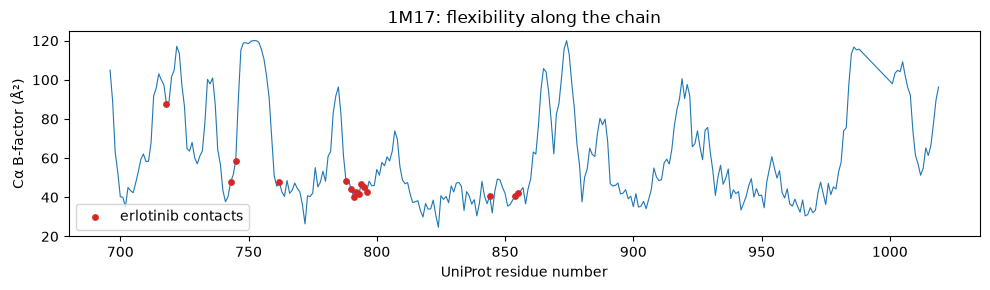

mean B: all Cα 60.6 | binding site Cα 47.8


In [11]:
ca_b = pd.DataFrame([{"pdb_resnum": r.id[1], "B": r["CA"].get_bfactor()} for r in chain if r.id[0] == " " and "CA" in r])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(ca_b["pdb_resnum"] + offset, ca_b["B"], lw=0.8)
ax.scatter(site["uniprot_resnum"], ca_b.set_index("pdb_resnum").loc[site["pdb_resnum"], "B"], color="tab:red",
           zorder=3, s=15, label="erlotinib contacts")
ax.set_xlabel("UniProt residue number"); ax.set_ylabel("Cα B-factor (Å²)"); ax.legend()
ax.set_title("1M17: flexibility along the chain")
plt.tight_layout(); plt.show()
print("mean B: all Cα", round(ca_b["B"].mean(), 1), "| binding site Cα",
      round(ca_b.set_index("pdb_resnum").loc[site["pdb_resnum"], "B"].mean(), 1))

B-factors (temperature factors) measure positional uncertainty. Here the binding-site residues are
better ordered than the chain average, as is typical for residues holding a ligand.

## 8. How buried is the drug? (solvent-accessible surface area)

In [12]:
sr = ShrakeRupley()
sr.compute(ligand, level="R")                           # ligand alone
free = ligand.sasa
sr.compute(model, level="R")                            # ligand in the complex
bound = ligand.sasa
print(f"erlotinib SASA: free {free:.0f} Å², bound {bound:.0f} Å² -> {100 * (1 - bound / free):.0f}% buried")

erlotinib SASA: free 655 Å², bound 166 Å² -> 75% buried


## 9. Save the binding site as a PDB file

In [13]:
site_ids = set(site["pdb_resnum"])

class PocketSelect(Select):
    def accept_residue(self, residue):
        return residue.id[1] in site_ids and residue.id[0] == " " or residue is ligand

io = PDBIO()
io.set_structure(structure)
io.save("output/1M17_pocket.pdb", PocketSelect())
print(open("output/1M17_pocket.pdb").read().count("ATOM"), "ATOM records and",
      open("output/1M17_pocket.pdb").read().count("HETATM"), "HETATM records written")

124 ATOM records and 29 HETATM records written


Open `output/1M17_pocket.pdb` in PyMOL, ChimeraX, or [Mol*](https://molstar.org/viewer/) to see the pocket.

### ✏️ Exercise 1

Which binding-site residue makes the **closest** contact to erlotinib? Report it in both PDB and UniProt
numbering.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
best = site.sort_values("min_dist_A").iloc[0]
print(f"{best.residue}{best.pdb_resnum} (UniProt {best.residue}{best.uniprot_resnum}) at {best.min_dist_A} Å")
```

</details>

### ✏️ Exercise 2

Is the osimertinib cysteine (UniProt **C797**) within 4 Å of erlotinib? Compute its minimum distance to the
ligand.

In [15]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
cys = chain[797 - offset]
print(cys.get_resname(), cys.id[1], "-> min distance", round(min(float(a - b) for a in cys for b in ligand), 2), "Å")
```

</details>

### ✏️ Exercise 3

Count the water molecules within 3.5 Å of any ligand atom: these may mediate ligand-protein hydrogen bonds.

In [16]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
waters = {a.get_parent().id for la in ligand for a in ns.search(la.coord, 3.5) if a.get_parent().id[0] == "W"}
print(len(waters), "water(s):", sorted(w[1] for w in waters))
```

</details>

## Key takeaways

- `PDBList` downloads, `MMCIFParser`/`PDBParser` parse; `MMCIF2Dict` reads metadata.
- Navigate Structure → Model → Chain → Residue → Atom; `atom1 - atom2` gives a distance in Å.
- **Always map PDB numbering to UniProt** before comparing residues across sources (here +24).
- `NeighborSearch`, B-factors, and SASA turn a structure into a binding-site description.

**Next:** [11 · Phylogenetics](11_phylogenetics.ipynb).